#### EDA- demand changes across locations, charger types, and times of day.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [9]:
df = pd.read_csv('D:/Capstoneproject2-EV/notebooks/cleaned_charging_records.csv')

## Convert date column to datetime
df['StartDatetime'] = pd.to_datetime(df['StartDatetime'])
df['EndDatetime'] = pd.to_datetime(df['EndDatetime'])


In [10]:
df.head()

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81


In [11]:
df.shape   ### Check the clean rows and columns 

(72108, 13)

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72108 entries, 0 to 72107
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   UserID          72108 non-null  int64         
 1   ChargerID       72108 non-null  int64         
 2   ChargerCompany  72108 non-null  int64         
 3   Location        72108 non-null  str           
 4   ChargerType     72108 non-null  int64         
 5   StartDay        72108 non-null  str           
 6   StartTime       72108 non-null  str           
 7   EndDay          72108 non-null  str           
 8   EndTime         72108 non-null  str           
 9   StartDatetime   72108 non-null  datetime64[us]
 10  EndDatetime     72108 non-null  datetime64[us]
 11  Duration        72108 non-null  int64         
 12  Demand          72108 non-null  float64       
dtypes: datetime64[us](2), float64(1), int64(5), str(5)
memory usage: 10.2 MB


In [13]:
sns.set_theme(style='whitegrid')
#### Summary description of demand and duration
df[['Demand', 'Duration']].describe().round(2)

,Demand,Duration
count,72108.00,72108.00
mean,17.57,152.73
std,13.46,146.36
min,0.01,1.00
25%,7.70,41.00
50%,14.26,114.00
75%,23.20,203.00
max,97.00,1573.00


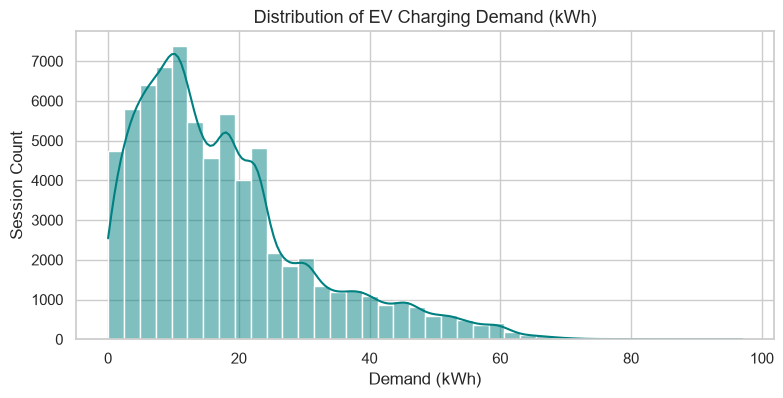

In [ ]:
### Target Variable (Demand)   ### univariate
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(9, 4))
sns.histplot(df['Demand'], bins=40, kde=True, color='teal')
plt.title('Distribution of EV Charging Demand (kWh)', fontsize=13)
plt.xlabel('Demand (kWh)')
plt.ylabel('Session Count')
plt.show()

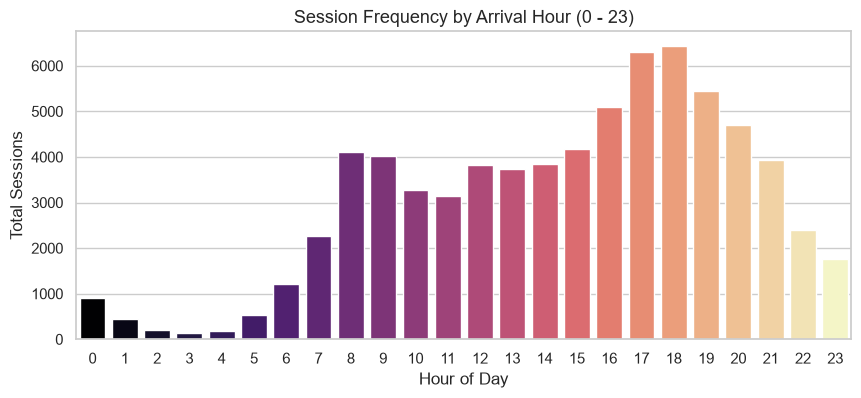

In [ ]:
#### frequency distribution of a single column (starthour) across sessions 
### Charging demand highly depends on human daily work routine ###

df['StartHour'] = df['StartDatetime'].dt.hour

plt.figure(figsize=(10, 4))
sns.countplot(x='StartHour', data=df, hue='StartHour', palette='magma', legend=False)
plt.title('Session Frequency by Arrival Hour (0 - 23)', fontsize=13)
plt.xlabel('Hour of Day')
plt.ylabel('Total Sessions')
plt.show()

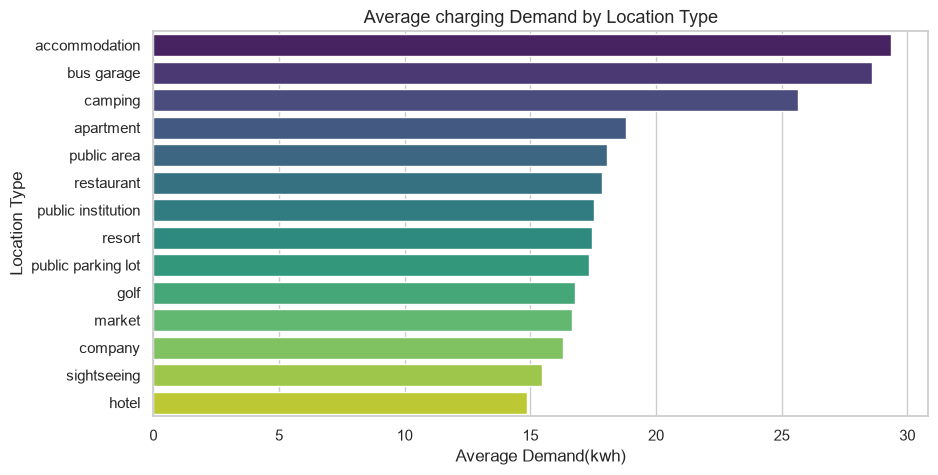

In [28]:
### Bivariate --DEmand Vs Location ###
avg_loc = df.groupby('Location')['Demand'].mean().sort_values(ascending=False)

plt.figure(figsize=(10,5))
sns.barplot(x=avg_loc.values, y=avg_loc.index, hue=avg_loc.index, palette='viridis',legend=False)
plt.title('Average charging Demand by Location Type', fontsize=13)
plt.xlabel('Average Demand(kwh)')
plt.ylabel('Location Type')
plt.show()

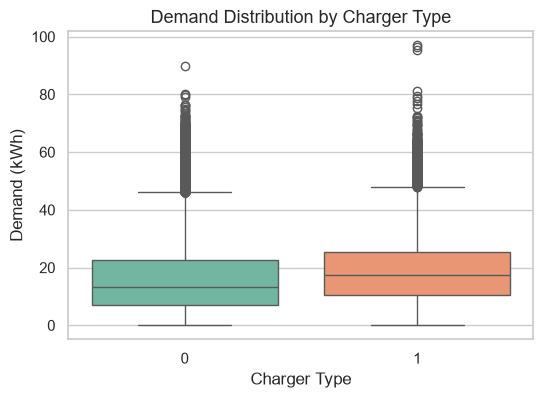

In [26]:
### Bivariate -Boxplot - Demand vs Charger Type: 
plt.figure(figsize=(6, 4))
sns.boxplot(x='ChargerType', y='Demand', data=df, hue='ChargerType',palette='Set2', legend=False)
plt.title('Demand Distribution by Charger Type', fontsize=13)
plt.xlabel('Charger Type')
plt.ylabel('Demand (kWh)')
plt.show()

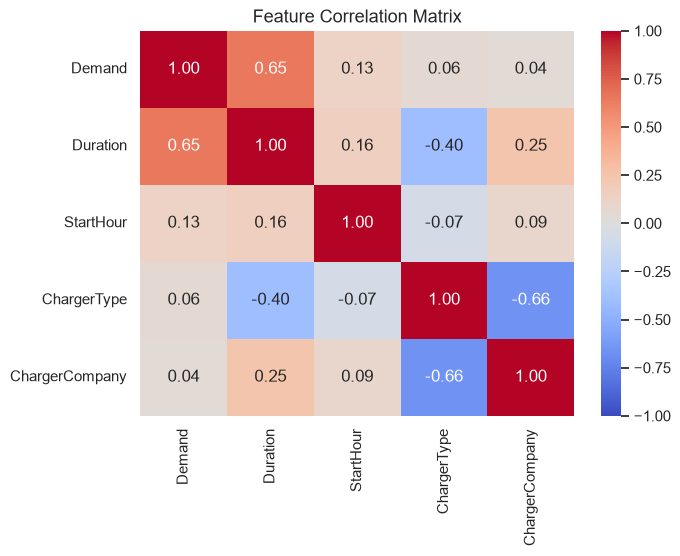

In [29]:
#### Correlation matrix of numerical features
numeric_cols = ['Demand', 'Duration', 'StartHour', 'ChargerType', 'ChargerCompany']

plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Feature Correlation Matrix', fontsize=13)
plt.show()